# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 * 1 / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = 400 * frames_per_day * 1920 * 1080 * 3 / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = 400 * (10 * 24 * 3600) * 640 * 360 * 3 / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

**Spatial:** a licence plate or a face. At 640×360 only 11.11% of the pixels per frame remain, and interpolation (Slide 13) can only smooth between the pixels that survive; it cannot recreate the lost high-frequency detail, so a plate that was readable at 1080p becomes a blur that can never be recovered. **Temporal:** the exact instant and path of fast motion. At 10 fps the gap between frames is 3× longer, so a quick action (the person starting to run, a hand-off) can fall between frames, and the object moves so far between frames that it is hard to match it from one frame to the next (correspondence problem, Slides 36-37). Storage drops from 5,866 TB/day to 217 TB/day, but these two pieces of evidence are gone forever.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

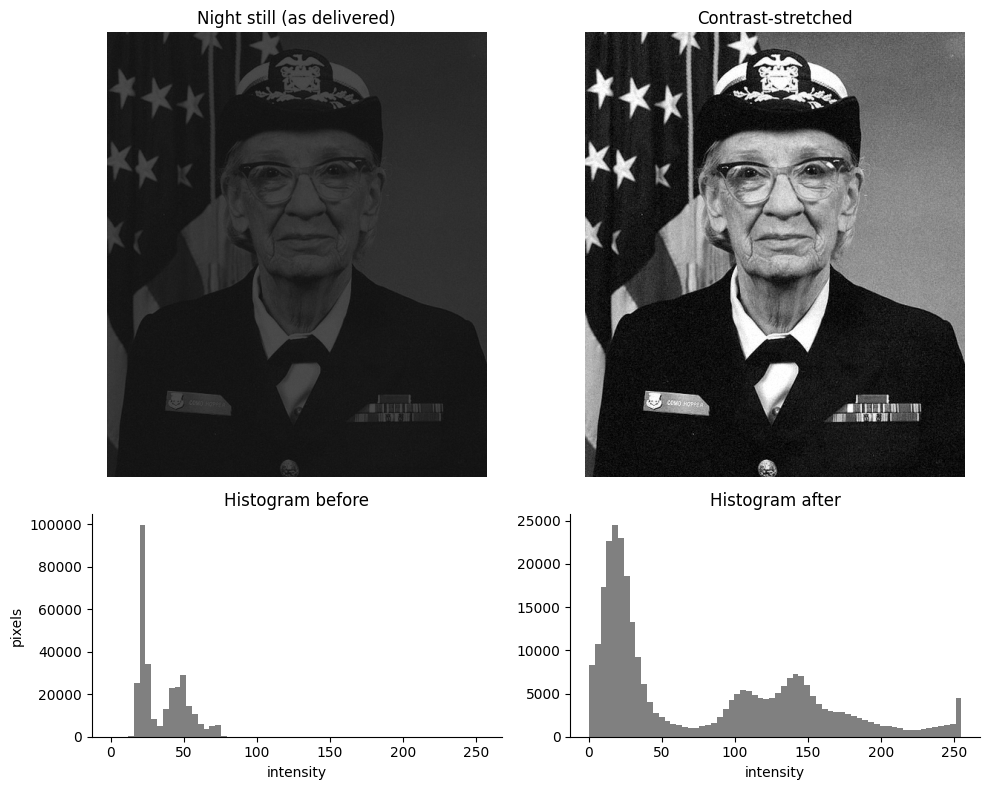

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

q1, q99 = np.percentile(stretched, [1, 99])
c_after = michelson(q99, q1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("Night still (as delivered)"); axes[0, 0].axis("off")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255); axes[0, 1].set_title("Contrast-stretched"); axes[0, 1].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray"); axes[1, 0].set(title="Histogram before", xlabel="intensity", ylabel="pixels")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="gray"); axes[1, 1].set(title="Histogram after", xlabel="intensity")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The histogram is a single narrow, low-key (dark, left-shifted) hump: almost all pixels sit between about 13 and 79 out of 0-255, with nothing in the mid-tones or highlights, which in the Slide 18 vocabulary is an under-exposed, low-contrast image (robust Michelson contrast 0.609 before). Stretching the 1st-99th percentile range onto 0-255 spreads the same grey levels over the whole display range, so differences the eye could not separate become visible, but no new information is created (it is a linear remap, and it amplifies the noise too). A histogram alone could never say *what* is in the picture because it throws away where pixels are: shuffle the pixels and the histogram is identical ("Same Histogram ≠ Same Image"). Note: after the stretch the Michelson contrast prints 1.000 because L_min becomes 0, so that number is a property of the stretch, not extra quality.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (speed < 3 px/s): [(np.float64(68.7), np.float64(78.1))]
Running  (speed > 25 px/s): [(np.float64(78.6), np.float64(86.0))]
Person stands still: frame 2061 at 68.70 s
Audio spike: frame 2250 at 75.00 s
Person starts running: frame 2358 at 78.60 s
Lighting jump: frame 3000 at 100.00 s


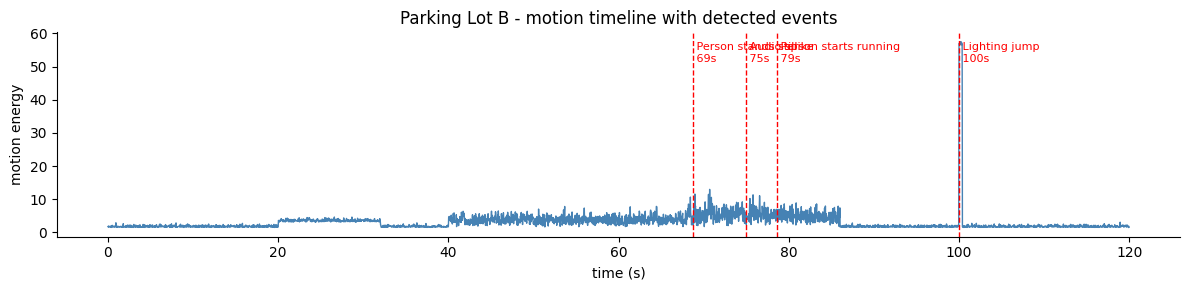

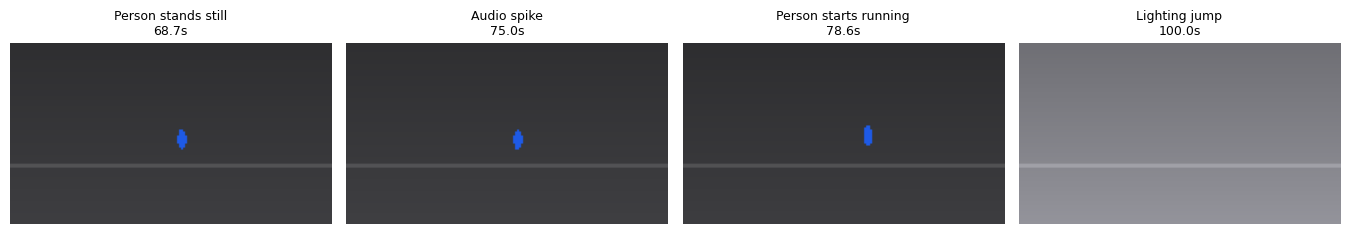

In [4]:
# TODO 1: person speed (px/s) - 1-second window (30 frames) to suppress tracking jitter
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))
t = cctv.time_s.values

# TODO 2: standing / running time ranges (first and last time of each, merging gaps < 1 s)
def ranges(mask, merge_gap=1.0):
    m = mask.fillna(False).values
    out, i = [], 0
    while i < len(m):
        if m[i]:
            j = i
            while j + 1 < len(m) and m[j + 1]: j += 1
            out.append([t[i], t[j]]); i = j + 1
        else:
            i += 1
    merged = [out[0]]
    for a, b in out[1:]:
        if a - merged[-1][1] < merge_gap: merged[-1][1] = b
        else: merged.append([a, b])
    return merged
print("Standing (speed < 3 px/s):", [(round(a, 1), round(b, 1)) for a, b in ranges(speed < 3)])
print("Running  (speed > 25 px/s):", [(round(a, 1), round(b, 1)) for a, b in ranges(speed > 25)])

# TODO 3: event frame indices
audio_event_idx = int(np.argmax(cctv.audio_level_db.values > -20))
lighting_event_idx = int(np.argmax(cctv.mean_brightness.diff().abs().values > 40))
stand_idx = int(np.argmax((speed < 3).fillna(False).values))
run_idx = int(np.argmax((speed > 25).fillna(False).values))
events = sorted([("Person stands still", stand_idx), ("Audio spike", audio_event_idx),
                 ("Person starts running", run_idx), ("Lighting jump", lighting_event_idx)], key=lambda e: e[1])
for name, i in events: print(f"{name}: frame {i} at {cctv.time_s[i]:.2f} s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, color="steelblue", lw=1)
for name, i in events:
    ax.axvline(cctv.time_s[i], color="red", ls="--", lw=1)
    ax.text(cctv.time_s[i], ax.get_ylim()[1] * 0.95, f" {name}\n {cctv.time_s[i]:.0f}s", va="top", fontsize=8, color="red")
ax.set(xlabel="time (s)", ylabel="motion energy", title="Parking Lot B - motion timeline with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axs = plt.subplots(1, len(events), figsize=(3.4 * len(events), 2.4))
for a, (name, i) in zip(axs, events):
    a.imshow(render_frame(cctv.iloc[i])); a.set_title(f"{name}\n{cctv.time_s[i]:.1f}s", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform keyframes every 20 s (t = 0, 20, 40, 60, 80, 100) would most likely miss the **audio event at 75 s** (a short burst falling between the 60 s and 80 s samples) and the **moment the person stops/starts moving (68.7 s and 78.6 s)**; only the lighting jump at 100 s happens to land on the grid, by luck. Uniform sampling ignores the content, so it wastes frames on the empty minutes and skips the short busy ones. The approach I used instead (motion vectors → events → one frame per event) is **content-based keyframe extraction** (Slide 40).

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

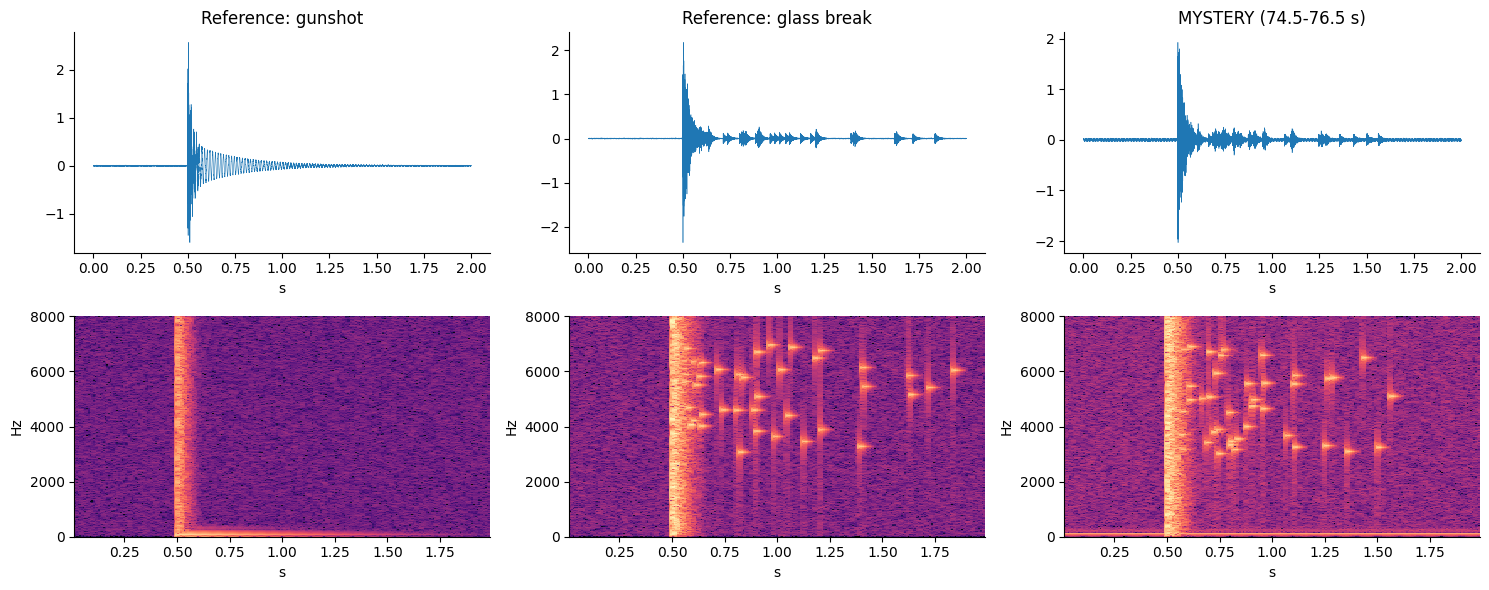

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: the mystery sound is a GLASS BREAK (high-frequency energy fraction 0.87 vs glass 0.99 and gunshot 0.00).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
tt = np.arange(int(2 * FS)) / FS
hf_fraction = {}
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for k, (name, x) in enumerate(clips.items()):
    axes[0, k].plot(tt, x, lw=0.4); axes[0, k].set_title(name); axes[0, k].set_xlabel("s")
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, k].pcolormesh(ts, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
    axes[1, k].set_ylim(0, 8000); axes[1, k].set_xlabel("s"); axes[1, k].set_ylabel("Hz")
    # TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact at 0.5 s -> 0.7-1.7 s)
    seg = (ts >= 0.7) & (ts <= 1.7)
    hf_fraction[name] = float(S[f > 3000][:, seg].sum() / S[:, seg].sum())

plt.tight_layout(); plt.show()

print({k: round(v, 3) for k, v in hf_fraction.items()})
# TODO 4: verdict
m, g, gl = hf_fraction["MYSTERY (74.5-76.5 s)"], hf_fraction["Reference: gunshot"], hf_fraction["Reference: glass break"]
verdict = "GLASS BREAK" if abs(m - gl) < abs(m - g) else "GUNSHOT"
print(f"Verdict: the mystery sound is a {verdict} (high-frequency energy fraction {m:.2f} vs glass {gl:.2f} and gunshot {g:.2f}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

Not confidently. All three waveforms share the same loud, sharp onset at 0.5 s; the tails differ only subtly (a smooth decay for the gunshot, small bursts for glass) and the mystery tail is noisy, so loudness-versus-time alone leaves it ambiguous. The spectrogram adds the missing dimensions: **time × frequency × magnitude** (colour/intensity) (Slide 57). The deciding pattern was the **scattered high-frequency specks** (the glass tinkle between ~3 and 7 kHz after the impact); the gunshot shows a vertical stripe plus a low-frequency band and nothing afterwards. Numerically, the fraction of energy above 3 kHz in 0.2-1.2 s after the impact is 0.003 for the gunshot, 0.989 for glass and 0.873 for the mystery sound, so it is a **glass break**.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

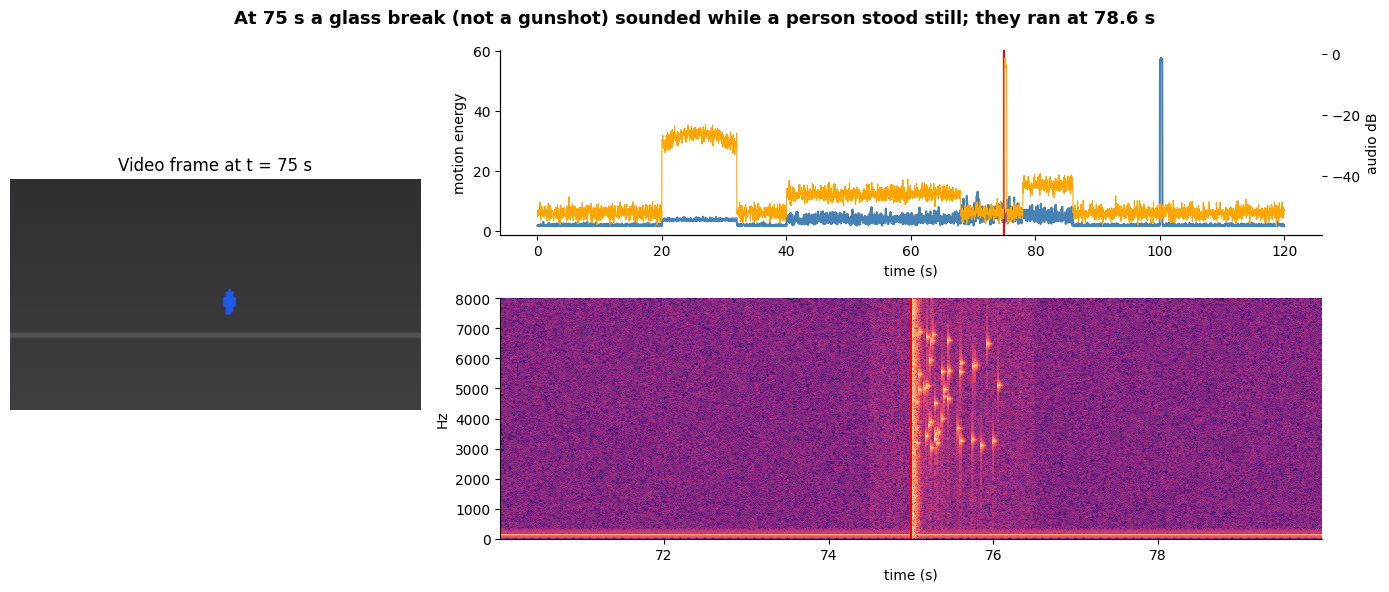

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
a0 = fig.add_subplot(gs[:, 0]); a0.imshow(render_frame(cctv.iloc[int(t_sel * FPS)])); a0.set_title("Video frame at t = 75 s"); a0.axis("off")
a1 = fig.add_subplot(gs[0, 1]); a1.plot(cctv.time_s, cctv.motion_energy, color="steelblue")
a1b = a1.twinx(); a1b.plot(cctv.time_s, cctv.audio_level_db, color="orange", lw=0.8)
a1.axvline(t_sel, color="red"); a1.set(ylabel="motion energy", xlabel="time (s)"); a1b.set_ylabel("audio dB")
a2 = fig.add_subplot(gs[1, 1]); f, ts, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
a2.pcolormesh(ts + 70, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma"); a2.set_ylim(0, 8000)
a2.axvline(t_sel, color="red"); a2.set(xlabel="time (s)", ylabel="Hz")
fig.suptitle("At 75 s a glass break (not a gunshot) sounded while a person stood still; they ran at 78.6 s", fontsize=13, fontweight="bold")

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

If the audio were offset by +2 s, the crack would appear at about 77 s instead of 75 s, so the briefing would show the person still standing at the moment the sound is displayed and the sound arriving just before they run (78.6 s). A reader would wrongly conclude that the sound *caused* or *immediately preceded* the running, or that the video and audio describe different events. The **timeline panel (top right)** would make the mistake visible: the audio spike would sit away from the red 75 s marker, and the **spectrogram panel** would show the impact 2 s to the right of the marker instead of exactly on it. Synchronization has to be verified, and too many panels at once risk information overload, which is why the common time marker matters.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

At about 75 s a glass break (not a gunshot) sounded in Lot B while a lone person had been standing still since 68.7 s; the person ran from 78.6 s to 86 s, and the lighting jumped from 62 to 148 at 100 s. I would open the briefing with the synchronized view (Task 5): it follows "overview first" (full 120 s timeline) with detail on demand at the selected moment, and every claim is backed by two modalities at the same timestamp (video frame + spectrogram), which is what separates glass (scattered high-frequency specks) from a gunshot. For storage I would not keep 1080p/30 fps everywhere (5,866 TB/day for 400 cameras): record at 360p/10 fps by default (217 TB/day, ~96% less) and keep full-resolution, 30 fps video and full-bandwidth audio only around detected events. The one thing it must not sacrifice is the **temporal resolution (30 fps) and full audio bandwidth inside event windows**, because the event order (sound at 75 s, running at 78.6 s) and the high-frequency content that identified glass cannot be recovered from the downsampled copy.